In [5]:
pip install pandas numpy matplotlib seaborn scikit-learn


Note: you may need to restart the kernel to use updated packages.


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


In [7]:
df = pd.read_csv("dataset/customer_churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [8]:
df.columns.tolist()

['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

In [9]:
print("Number of Customers:", df.shape[0])
print("Number of Features:", df.shape[1])

Number of Customers: 7043
Number of Features: 21


In [10]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [11]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [12]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


In [13]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [14]:
df["Churn"].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

In [15]:
print("Total Missing Values:", df.isnull().sum().sum())

Total Missing Values: 0


In [16]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

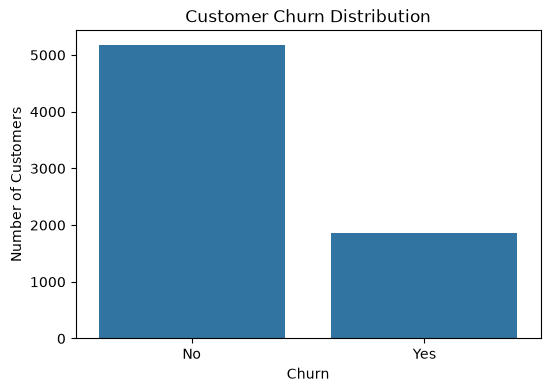

In [17]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

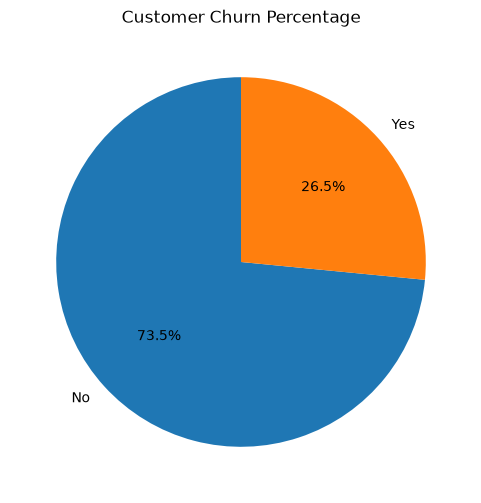

In [18]:
churn_counts = df["Churn"].value_counts()
plt.figure(figsize=(6, 6))
plt.pie(
    churn_counts,
    labels=churn_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Customer Churn Percentage")
plt.show()

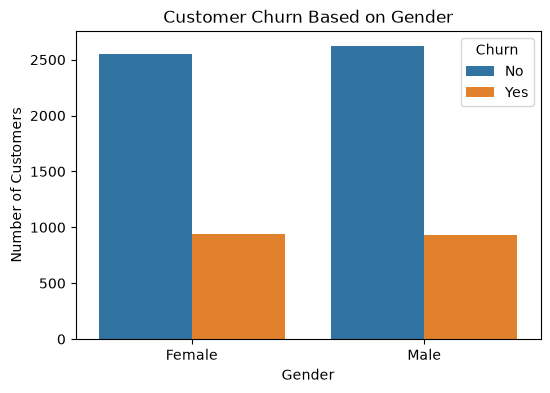

In [19]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="gender", hue="Churn")
plt.title("Customer Churn Based on Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.show()

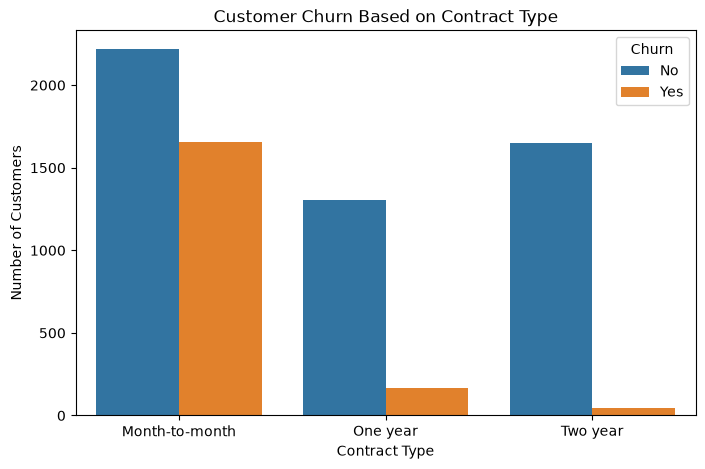

In [20]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Customer Churn Based on Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.show()

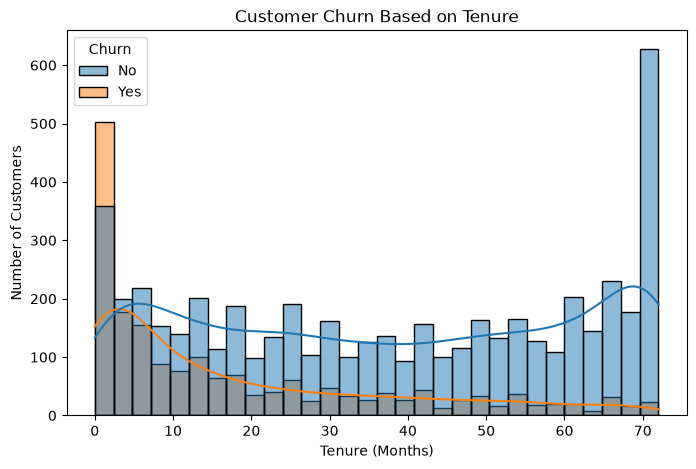

In [21]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="tenure", hue="Churn",
             bins=30, kde=True)

plt.title("Customer Churn Based on Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")
plt.show()

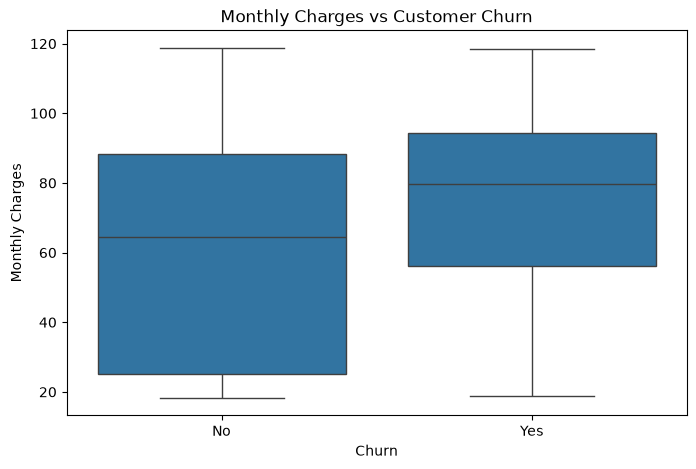

In [22]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.show()

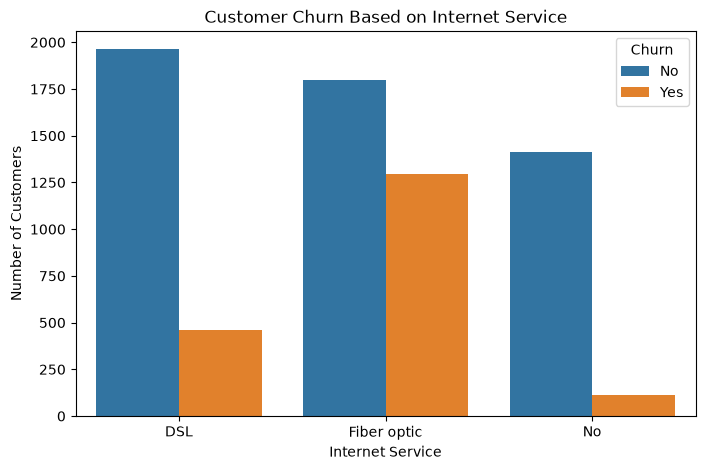

In [23]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="InternetService", hue="Churn")
plt.title("Customer Churn Based on Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")
plt.show()

In [24]:
df_clean = df.copy()


In [25]:
df_clean = df_clean.drop("customerID", axis=1)
df_clean.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [26]:
print(df_clean["TotalCharges"].dtype)

str


In [27]:
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce"
)


In [28]:
df_clean.isnull().sum()

gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [29]:
df_clean["TotalCharges"] = df_clean["TotalCharges"].fillna(
    df_clean["TotalCharges"].median()
)


In [30]:
print("Total Missing Values:", df_clean.isnull().sum().sum())

Total Missing Values: 0


In [31]:
categorical_columns = df_clean.select_dtypes(
    include=["object", "str"]
).columns
print("Categorical Columns:")
print(categorical_columns)

Categorical Columns:
Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod', 'Churn'],
      dtype='str')


In [32]:
label_encoders = {}
for column in categorical_columns:

    le = LabelEncoder()

    df_clean[column] = le.fit_transform(df_clean[column])

    label_encoders[column] = le



In [33]:
df_clean.head()


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,1,0,0,2,0,0,0,0,0,1,2,29.85,29.85,0
1,1,0,0,0,34,1,0,0,2,0,2,0,0,0,1,0,3,56.95,1889.50,0
2,1,0,0,0,2,1,0,0,2,2,0,0,0,0,0,1,3,53.85,108.15,1
3,1,0,0,0,45,0,1,0,2,0,2,2,0,0,1,0,0,42.30,1840.75,0
4,0,0,0,0,2,1,0,1,0,0,0,0,0,0,0,1,2,70.70,151.65,1


In [34]:
df_clean.dtypes

gender                int64
SeniorCitizen         int64
Partner               int64
Dependents            int64
tenure                int64
PhoneService          int64
MultipleLines         int64
InternetService       int64
OnlineSecurity        int64
OnlineBackup          int64
DeviceProtection      int64
TechSupport           int64
StreamingTV           int64
StreamingMovies       int64
Contract              int64
PaperlessBilling      int64
PaymentMethod         int64
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
dtype: object

In [35]:
X = df_clean.drop("Churn", axis=1)
y = df_clean["Churn"]
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7043, 19)
Target shape: (7043,)


In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5634, 19)
Testing data: (1409, 19)


In [37]:
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Total samples:", len(X_train) + len(X_test))

Training samples: 5634
Testing samples: 1409
Total samples: 7043


In [38]:
model_df = df.drop("customerID", axis=1).copy()
model_df["TotalCharges"] = pd.to_numeric(
    model_df["TotalCharges"],
    errors="coerce"
)
model_df["TotalCharges"] = model_df["TotalCharges"].fillna(
    model_df["TotalCharges"].median()
)



In [39]:
X = model_df.drop("Churn", axis=1)
y = model_df["Churn"].map({"No": 0, "Yes": 1})
X = pd.get_dummies(X, drop_first=True, dtype=int)
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7043, 30)
Target shape: (7043,)


In [40]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5634, 30)
Testing data: (1409, 30)


In [41]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [45]:
log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train_scaled, y_train)
print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


In [43]:
y_pred_log = log_model.predict(X_test_scaled)
print("Predictions completed successfully!")

Predictions completed successfully!


In [46]:
log_accuracy = accuracy_score(y_test, y_pred_log)
print("Logistic Regression Accuracy:", log_accuracy * 100, "%")

Logistic Regression Accuracy: 80.69552874378992 %


In [47]:
print(classification_report(y_test, y_pred_log))

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.57      0.61       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



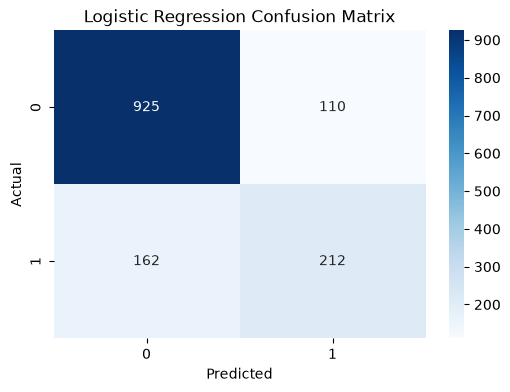

In [48]:
cm = confusion_matrix(y_test, y_pred_log)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [49]:
print("Logistic Regression Accuracy:", log_accuracy * 100, "%")

Logistic Regression Accuracy: 80.69552874378992 %


In [50]:
print(classification_report(y_test, y_pred_log))


              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.57      0.61       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [51]:
print(confusion_matrix(y_test, y_pred_log))

[[925 110]
 [162 212]]


In [52]:
dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=5
)
dt_model.fit(X_train, y_train)
print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [53]:
y_pred_dt = dt_model.predict(X_test)
print("Decision Tree predictions completed!")

Decision Tree predictions completed!


In [54]:
dt_accuracy = accuracy_score(y_test, y_pred_dt)
print("Decision Tree Accuracy:", dt_accuracy * 100, "%")

Decision Tree Accuracy: 79.4180269694819 %


In [55]:
print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

           0       0.84      0.88      0.86      1035
           1       0.63      0.55      0.58       374

    accuracy                           0.79      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.79      0.79      0.79      1409



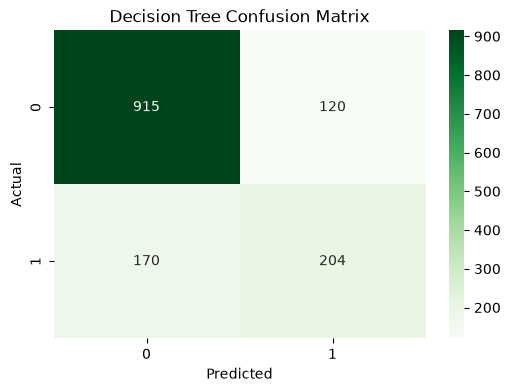

In [56]:
cm_dt = confusion_matrix(y_test, y_pred_dt)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_dt, annot=True, fmt="d", cmap="Greens")
plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [57]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    max_depth=10
)
rf_model.fit(X_train, y_train)
print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [58]:
y_pred_rf = rf_model.predict(X_test)
print("Random Forest predictions completed!")

Random Forest predictions completed!


In [59]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)
print("Random Forest Accuracy:", rf_accuracy * 100, "%")

Random Forest Accuracy: 80.69552874378992 %


In [60]:
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.84      0.91      0.87      1035
           1       0.67      0.53      0.60       374

    accuracy                           0.81      1409
   macro avg       0.76      0.72      0.73      1409
weighted avg       0.80      0.81      0.80      1409



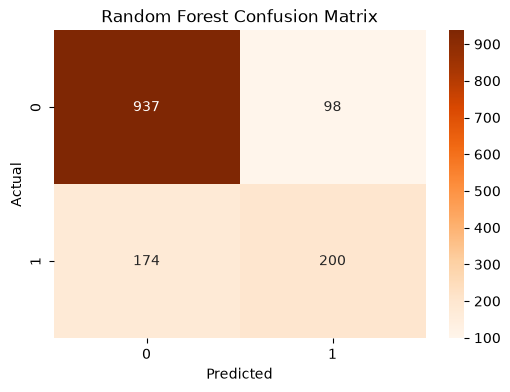

In [61]:
cm_rf = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Oranges")
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [62]:
model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],

    "Accuracy": [
        log_accuracy * 100,
        dt_accuracy * 100,
        rf_accuracy * 100
    ]
})
print(model_results)

                 Model   Accuracy
0  Logistic Regression  80.695529
1        Decision Tree  79.418027
2        Random Forest  80.695529


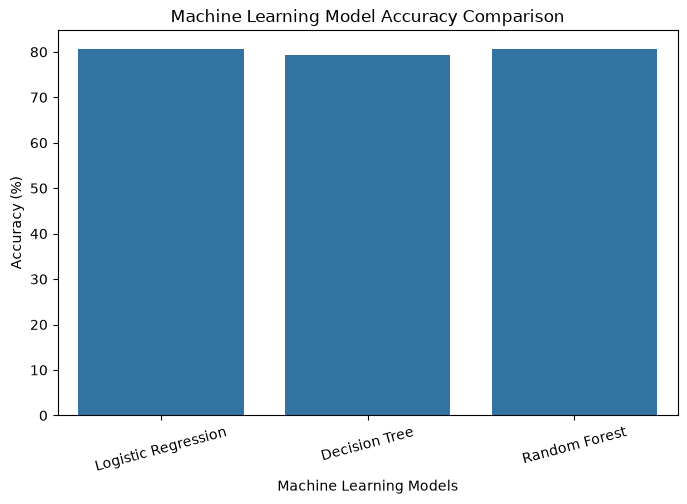

In [63]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=model_results,
    x="Model",
    y="Accuracy"
)
plt.title("Machine Learning Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=15)
plt.show()

In [64]:
from sklearn.metrics import precision_score, recall_score, f1_score
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],

    "Accuracy": [
        accuracy_score(y_test, y_pred_log),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf)
    ],

    "Precision": [
        precision_score(y_test, y_pred_log),
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_rf)
    ],

    "Recall": [
        recall_score(y_test, y_pred_log),
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_rf)
    ],

    "F1 Score": [
        f1_score(y_test, y_pred_log),
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_rf)
    ]
})
print(comparison.round(3))

                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression     0.807      0.658   0.567     0.609
1        Decision Tree     0.794      0.630   0.545     0.585
2        Random Forest     0.807      0.671   0.535     0.595


In [65]:
best_model_name = comparison.loc[
    comparison["F1 Score"].idxmax(), "Model"
]
print("Best Model:", best_model_name)

Best Model: Logistic Regression


In [66]:
models = {
    "Logistic Regression": log_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model
}
best_model = models[best_model_name]
print("Best model selected:", best_model_name)

Best model selected: Logistic Regression


In [67]:
if best_model_name == "Logistic Regression":
    final_predictions = best_model.predict(X_test_scaled)
else:
    final_predictions = best_model.predict(X_test)
print("Final predictions completed!")

Final predictions completed!


In [68]:
results = pd.DataFrame({
    "Actual Churn": y_test.values,
    "Predicted Churn": final_predictions
})
print(results.head(10))

   Actual Churn  Predicted Churn
0             0                0
1             0                1
2             0                0
3             0                0
4             0                0
5             0                1
6             0                0
7             0                0
8             0                0
9             1                0


In [69]:
print(comparison.round(3))
print("\nBest Model:", best_model_name)


                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression     0.807      0.658   0.567     0.609
1        Decision Tree     0.794      0.630   0.545     0.585
2        Random Forest     0.807      0.671   0.535     0.595

Best Model: Logistic Regression


In [70]:
import pickle
with open("churn_model.pkl", "wb") as file:
    pickle.dump(best_model, file)

print("Best model saved successfully!")

Best model saved successfully!


In [71]:
import pickle
with open("churn_model.pkl", "rb") as file:
    loaded_model = pickle.load(file)
test_predictions = loaded_model.predict(X_test_scaled)
print("First 10 predictions:", test_predictions[:10])

First 10 predictions: [0 1 0 0 0 1 0 0 0 0]


In [72]:
new_customer = X.iloc[[0]]
new_customer_scaled = scaler.transform(new_customer)
prediction = loaded_model.predict(new_customer_scaled)
if prediction[0] == 1:
    print("Customer is likely to Churn")
else:
    print("Customer is likely to Stay")

Customer is likely to Churn


In [75]:
pip install xgboost imbalanced-learn


Note: you may need to restart the kernel to use updated packages.


In [77]:
from xgboost import XGBClassifier
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.1,
    random_state=42,
    eval_metric='logloss'
)
xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)


In [79]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
print("Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("Precision:", precision_score(y_test, y_pred_xgb))
print("Recall:", recall_score(y_test, y_pred_xgb))
print("F1 Score:", f1_score(y_test, y_pred_xgb))
print("ROC-AUC:", roc_auc_score(y_test, xgb_model.predict_proba(X_test)[:, 1]))

Accuracy: 0.8019872249822569
Precision: 0.6567656765676567
Recall: 0.5320855614973262
F1 Score: 0.5878877400295421
ROC-AUC: 0.8435660957400087


In [80]:
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(
    X_train, y_train
)
print("Before SMOTE:")
print(y_train.value_counts())
print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

Before SMOTE:
Churn
0    4139
1    1495
Name: count, dtype: int64

After SMOTE:
Churn
0    4139
1    4139
Name: count, dtype: int64


In [85]:
log_smote_model = LogisticRegression(max_iter=1000)
log_smote_model.fit(X_train_smote, y_train_smote)
y_pred_log_smote = log_smote_model.predict(X_test_scaled)
print("Logistic Regression with SMOTE trained successfully!")

Logistic Regression with SMOTE trained successfully!


C:\Users\Dell\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\Users\Dell\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [86]:
from sklearn.linear_model import LogisticRegression
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)

X_train_scaled_smote, y_train_scaled_smote = smote.fit_resample(
    X_train_scaled, y_train
)
log_smote_model = LogisticRegression(max_iter=3000)
log_smote_model.fit(
    X_train_scaled_smote,
    y_train_scaled_smote
)
y_pred_log_smote = log_smote_model.predict(X_test_scaled)


In [87]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
print("Accuracy:", accuracy_score(y_test, y_pred_log_smote))
print("Precision:", precision_score(y_test, y_pred_log_smote))
print("Recall:", recall_score(y_test, y_pred_log_smote))
print("F1 Score:", f1_score(y_test, y_pred_log_smote))
print("ROC-AUC:", roc_auc_score(
    y_test,
    log_smote_model.predict_proba(X_test_scaled)[:, 1]
))

Accuracy: 0.7381121362668559
Precision: 0.5042301184433164
Recall: 0.7967914438502673
F1 Score: 0.6176165803108808
ROC-AUC: 0.8403239556692241


In [89]:
rf_smote_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    max_depth=10
)
rf_smote_model.fit(X_train_smote, y_train_smote)
y_pred_rf_smote = rf_smote_model.predict(X_test)


In [91]:
print("Accuracy:", accuracy_score(y_test, y_pred_rf_smote))
print("Precision:", precision_score(y_test, y_pred_rf_smote))
print("Recall:", recall_score(y_test, y_pred_rf_smote))
print("F1 Score:", f1_score(y_test, y_pred_rf_smote))
print("ROC-AUC:", roc_auc_score(
    y_test,
    rf_smote_model.predict_proba(X_test)[:, 1]
))

Accuracy: 0.7643718949609652
Precision: 0.5432098765432098
Recall: 0.7058823529411765
F1 Score: 0.6139534883720931
ROC-AUC: 0.8294014311917126


In [93]:
xgb_smote_model = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.1,
    random_state=42,
    eval_metric='logloss'
)
xgb_smote_model.fit(X_train_smote, y_train_smote)
y_pred_xgb_smote = xgb_smote_model.predict(X_test)


In [94]:
print("Accuracy:", accuracy_score(y_test, y_pred_xgb_smote))
print("Precision:", precision_score(y_test, y_pred_xgb_smote))
print("Recall:", recall_score(y_test, y_pred_xgb_smote))
print("F1 Score:", f1_score(y_test, y_pred_xgb_smote))
print("ROC-AUC:", roc_auc_score(
    y_test,
    xgb_smote_model.predict_proba(X_test)[:, 1]
))

Accuracy: 0.7714691270404542
Precision: 0.5593607305936074
Recall: 0.6550802139037433
F1 Score: 0.603448275862069
ROC-AUC: 0.8338926347877755


In [95]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
model_results = []
models = [
    ("Logistic Regression", log_model, X_test_scaled, y_pred_log),
    ("Decision Tree", dt_model, X_test, y_pred_dt),
    ("Random Forest", rf_model, X_test, y_pred_rf),
    ("XGBoost", xgb_model, X_test, y_pred_xgb),
    ("Logistic Regression + SMOTE", log_smote_model, X_test_scaled, y_pred_log_smote),
    ("Random Forest + SMOTE", rf_smote_model, X_test, y_pred_rf_smote),
    ("XGBoost + SMOTE", xgb_smote_model, X_test, y_pred_xgb_smote)
]

for name, model, X_data, predictions in models:
    probabilities = model.predict_proba(X_data)[:, 1]

    model_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

comparison_df = pd.DataFrame(model_results)

comparison_df = comparison_df.round(3)

comparison_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.807,0.658,0.567,0.609,0.842
1,Decision Tree,0.794,0.630,0.545,0.585,0.828
2,Random Forest,0.807,0.671,0.535,0.595,0.843
3,XGBoost,0.802,0.657,0.532,0.588,0.844
4,Logistic Regression + SMOTE,0.738,0.504,0.797,0.618,0.840
5,Random Forest + SMOTE,0.764,0.543,0.706,0.614,0.829
6,XGBoost + SMOTE,0.771,0.559,0.655,0.603,0.834


In [97]:
comparison_df.to_csv("model_comparison.csv", index=False)


Top 5 Churn Drivers:


,Feature,Importance
1,tenure,0.188226
3,TotalCharges,0.157077
2,MonthlyCharges,0.121407
10,InternetService_Fiber optic,0.068687
28,PaymentMethod_Electronic check,0.061691


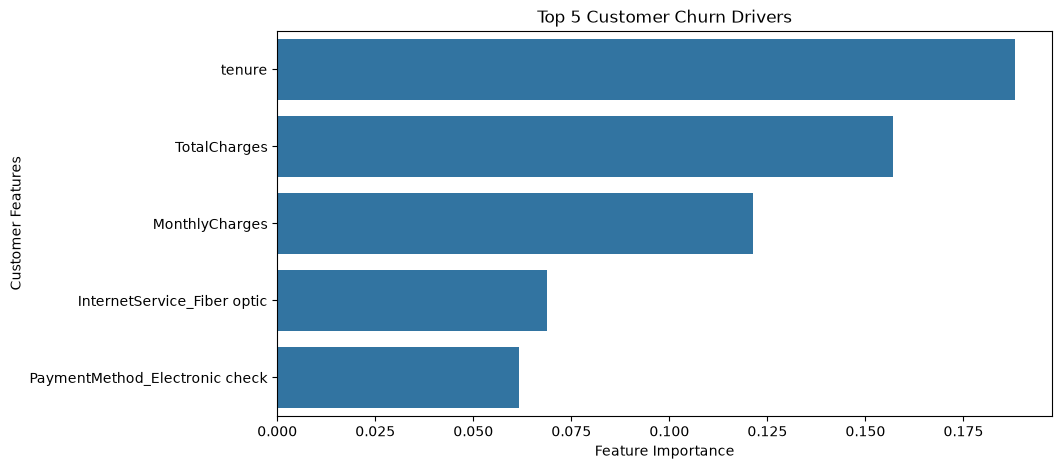

In [98]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance", ascending=False
)

top_5_features = feature_importance.head(5)

print("Top 5 Churn Drivers:")
display(top_5_features)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=top_5_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 5 Customer Churn Drivers")
plt.xlabel("Feature Importance")
plt.ylabel("Customer Features")
plt.show()

In [99]:
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[0, 12, 24, 48, 72],
    labels=["0-12 Months", "13-24 Months", "25-48 Months", "49-72 Months"]
)

tenure_analysis = df.groupby(
    "TenureGroup", observed=False
).agg(
    Total_Customers=("Churn", "count"),
    Churned_Customers=("Churn", lambda x: (x == "Yes").sum())
)

tenure_analysis["Churn_Rate"] = (
    tenure_analysis["Churned_Customers"] /
    tenure_analysis["Total_Customers"] * 100
)

tenure_analysis = tenure_analysis.round(2)

display(tenure_analysis)

,Total_Customers,Churned_Customers,Churn_Rate
TenureGroup,,,
0-12 Months,2175,1037,47.68
13-24 Months,1024,294,28.71
25-48 Months,1594,325,20.39
49-72 Months,2239,213,9.51


In [100]:
churned_customers = df[df["Churn"] == "Yes"].copy()

revenue_analysis = churned_customers.groupby(
    "TenureGroup", observed=False
).agg(
    Churned_Customers=("Churn", "count"),
    Average_Monthly_Charges=("MonthlyCharges", "mean"),
    Total_Monthly_Charges=("MonthlyCharges", "sum")
)

revenue_analysis = revenue_analysis.round(2)

display(revenue_analysis)

,Churned_Customers,Average_Monthly_Charges,Total_Monthly_Charges
TenureGroup,,,
0-12 Months,1037,66.49,68954.25
13-24 Months,294,78.51,23081.65
25-48 Months,325,84.50,27462.50
49-72 Months,213,92.17,19632.45


In [101]:
target_customers = 1037
monthly_discount = 10
offer_duration = 3
offer_cost_per_customer = monthly_discount * offer_duration
total_offer_cost = (
    target_customers * offer_cost_per_customer
)
monthly_revenue_at_risk = 68954.25
print("Target Customers:", target_customers)
print("Offer Cost Per Customer: $", offer_cost_per_customer)
print("Total Offer Cost: $", total_offer_cost)
print("Monthly Revenue Associated with Churn: $", monthly_revenue_at_risk)

Target Customers: 1037
Offer Cost Per Customer: $ 30
Total Offer Cost: $ 31110
Monthly Revenue Associated with Churn: $ 68954.25


In [102]:
average_monthly_charge = 66.49

revenue_per_retained_customer = (
    average_monthly_charge * 3
)
break_even_customers = (
    total_offer_cost / revenue_per_retained_customer
)

break_even_percentage = (
    break_even_customers / target_customers
) * 100

print("Break-even Customers:", round(break_even_customers, 2))

print("Break-even Retention Rate:",
      round(break_even_percentage, 2), "%")

Break-even Customers: 155.96
Break-even Retention Rate: 15.04 %


In [104]:
import pickle
model_bundle = {
    "model": log_smote_model,
    "scaler": scaler,
    "feature_columns": X.columns.tolist()
}

with open("churn_prediction_bundle.pkl", "wb") as file:
    pickle.dump(model_bundle, file)

